Epoch 10 / 100: Train Loss: 0.3613, Train Acc: 91.64%, Val Loss: 0.2761, Val Acc: 95.28%
Epoch 20 / 100: Train Loss: 0.1782, Train Acc: 95.36%, Val Loss: 0.1308, Val Acc: 98.33%
Epoch 30 / 100: Train Loss: 0.1010, Train Acc: 97.31%, Val Loss: 0.0843, Val Acc: 98.89%
Epoch 40 / 100: Train Loss: 0.0706, Train Acc: 98.05%, Val Loss: 0.0624, Val Acc: 98.89%
Epoch 50 / 100: Train Loss: 0.0553, Train Acc: 98.98%, Val Loss: 0.0440, Val Acc: 99.44%
Epoch 60 / 100: Train Loss: 0.0489, Train Acc: 98.79%, Val Loss: 0.0479, Val Acc: 98.33%
Epoch 70 / 100: Train Loss: 0.0343, Train Acc: 99.26%, Val Loss: 0.0378, Val Acc: 98.61%
Epoch 80 / 100: Train Loss: 0.0207, Train Acc: 99.54%, Val Loss: 0.0371, Val Acc: 99.17%
Epoch 90 / 100: Train Loss: 0.0276, Train Acc: 99.44%, Val Loss: 0.0363, Val Acc: 99.44%
Epoch 100 / 100: Train Loss: 0.0307, Train Acc: 98.98%, Val Loss: 0.0308, Val Acc: 99.17%

Training complete!
Best Test Accuracy: 99.44% at epoch 46


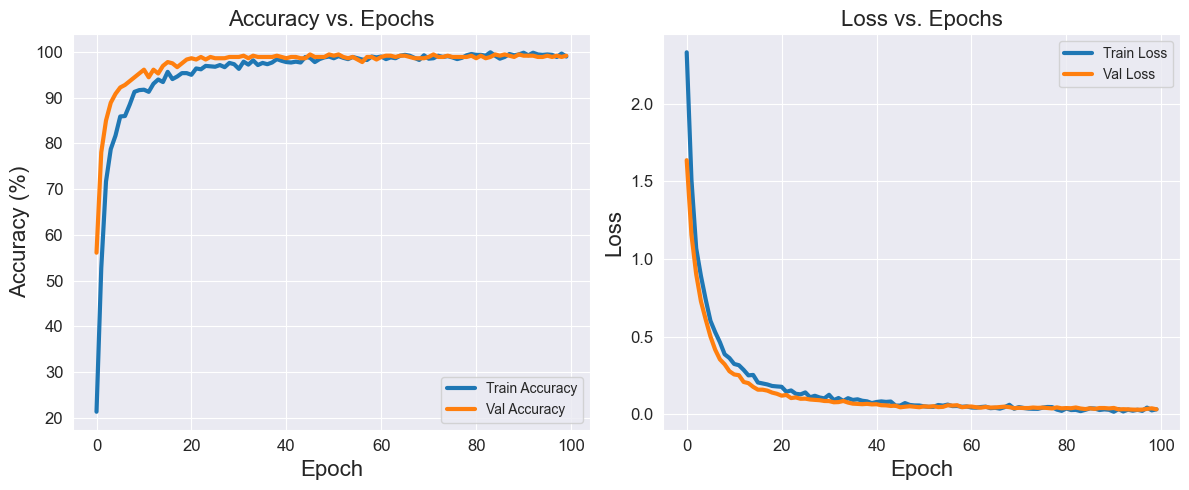

In [78]:
model_best = nn.Sequential(
    nn.Linear(64, 100),
    nn.BatchNorm1d(100),
    nn.ReLU(),
    nn.Dropout(p=0.2),  
    nn.Linear(100, 50),
    nn.BatchNorm1d(50),
    nn.ReLU(),
    nn.Dropout(p=0.2), 
    nn.Linear(50, 10),
)

model_best.apply(he_init_parameters)
optimizer = optim.Adam(model_best.parameters(), lr=0.001)
result = fit_model(model_best, loss_fn, optimizer, epochs=100)
plot_results(result)

In [ ]:
evaluate_model(model_best, test_loader)

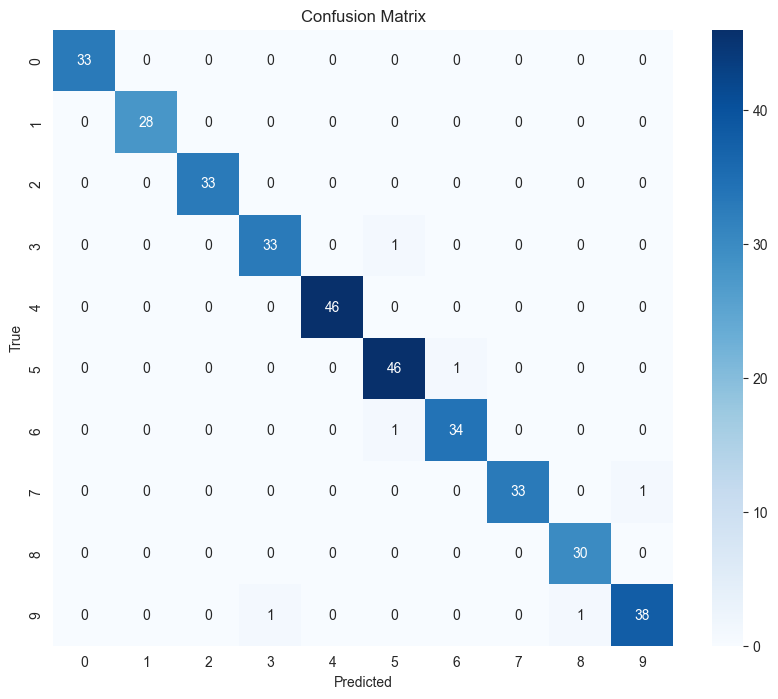

Confusion Matrix:
[[33  0  0  0  0  0  0  0  0  0]
 [ 0 28  0  0  0  0  0  0  0  0]
 [ 0  0 33  0  0  0  0  0  0  0]
 [ 0  0  0 33  0  1  0  0  0  0]
 [ 0  0  0  0 46  0  0  0  0  0]
 [ 0  0  0  0  0 46  1  0  0  0]
 [ 0  0  0  0  0  1 34  0  0  0]
 [ 0  0  0  0  0  0  0 33  0  1]
 [ 0  0  0  0  0  0  0  0 30  0]
 [ 0  0  0  1  0  0  0  0  1 38]]


In [79]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

def evaluate_model_with_confusion_matrix(model, test_loader):
    model.eval()
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for inputs, labels in test_loader:
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=range(10), 
                yticklabels=range(10))
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title('Confusion Matrix')
    plt.show()
    
    return cm

cm = evaluate_model_with_confusion_matrix(model_best, test_loader)
print("Confusion Matrix:")
print(cm)

In [90]:
def evaluate_with_errors(model, test_loader):
    model.eval()
    error_samples = []  # 存储所有错误样本的列表
    
    with torch.no_grad():
        for batch_idx, (inputs, labels) in enumerate(test_loader):
            outputs = model(inputs)
            outputs = torch.softmax(outputs, dim=1) # 计算每个类别的概率
            _, preds = torch.max(outputs, 1)
            
            wrong_indices = (preds != labels).nonzero(as_tuple=True)[0]
            for idx in wrong_indices:
                error_sample = {       
                    'features': inputs[idx].cpu().numpy().copy(),  
                    'true_label': labels[idx].item(),             
                    'pred_label': preds[idx].item(),             
                    'probabilities': outputs[idx].cpu().numpy().copy()
                }
                error_samples.append(error_sample)    
    return error_samples

error_data = evaluate_with_errors(model_best, test_loader)
print(f"\n总错误样本数: {len(error_data)}")


总错误样本数: 6


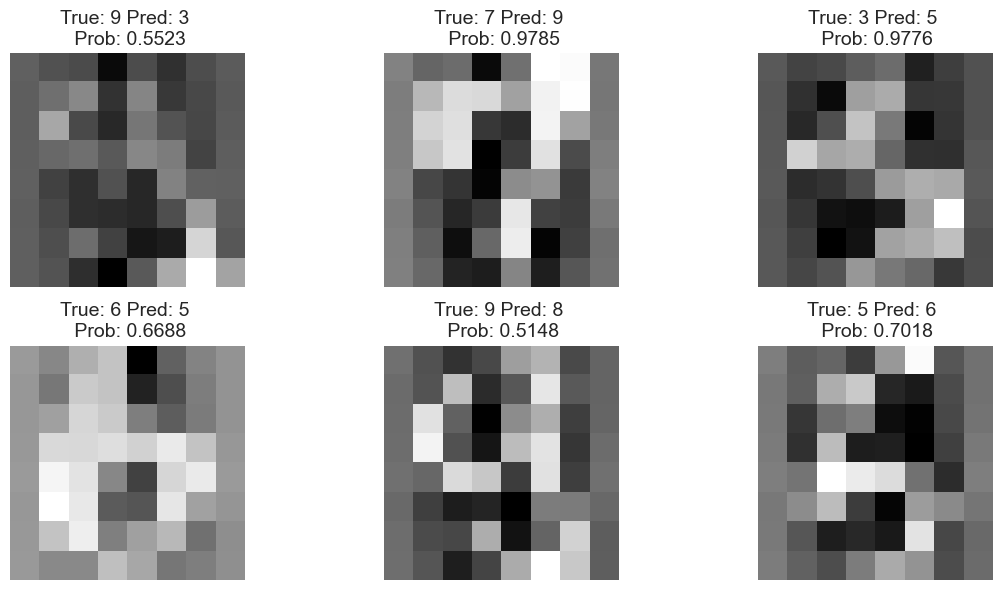

In [91]:
def plot_error_samples(error_data):
    num_samples = len(error_data)
    if num_samples == 0:
        print("No error samples to plot.")
        return
    
    max_cols = 3
    rows = (num_samples + max_cols - 1) // max_cols
    cols = min(num_samples, max_cols)
    
    fig, axes = plt.subplots(rows, cols, figsize=(cols*4, rows*3))
    if rows == 1:
        axes = axes.reshape(1, -1)
    elif cols == 1:
        axes = axes.reshape(-1, 1)
    for i in range(num_samples):
        row = i // max_cols
        col = i % max_cols
        ax = axes[row, col]
        
        sample = error_data[i]
        ax.imshow(sample['features'].reshape(8, 8), cmap='gray')
        ax.set_title(f"True: {sample['true_label']} Pred: {sample['pred_label']} \n Prob: {sample['probabilities'].max():.4f}" ,
                     fontsize=14)
        ax.axis('off')

    for i in range(num_samples, rows * cols):
        row = i // max_cols
        col = i % max_cols
        fig.delaxes(axes[row, col])
    
    plt.tight_layout()
    plt.show()

plot_error_samples(error_data)